# Dataset · Paths between stores

Run All for local GFQL queries, explicit path tables, and interactive Plotly charts.
Start with the controls below, then rerun the remaining cells to explore another store.

**Relationship paths** answer which spaces, floors, categories, and amenities connect
locations. A shared floor or category does not establish a walking route.
**Walking examples** use saved, directed SDK distances in metres. Their diagrams are
schematic: the snapshot has no saved route polylines or ordered intervening spaces.
No credentials or network access are needed. Hosted Graphistry rendering is optional
and disabled at the end.

In [1]:
import json
import sys
import unicodedata
from pathlib import Path

import duckdb
import pandas as pd
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "scripts/plazapd/mappedin.py").is_file()
             and (p / "pyproject.toml").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the repository or nbs/plazapd.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from scripts.plazapd.mappedin import load_tables

DATA_DIR = ROOT / "data/plazapd"
tables = load_tables(DATA_DIR, format="parquet")
manifest = json.loads((DATA_DIR / "manifest.json").read_text())


def text_key(value):
    return "".join(c for c in unicodedata.normalize("NFKD", value).casefold() if c.isalnum())


venue_aliases = {text_key(value) for value in [
    manifest.get("venue_name"), manifest.get("venue_id"), *tables["venues"].name.dropna()
] if isinstance(value, str) and value}


def venue_label(value):
    if isinstance(value, str) and any(alias in text_key(value) for alias in venue_aliases):
        return "Venue"
    return value


for table in tables.values():
    for column in ("name", "description"):
        if column in table:
            table[column] = table[column].map(venue_label).astype(table[column].dtype)

assert tables["entities"].entity_id.is_unique
assert tables["relationships"][["src", "dst"]].isin(set(tables["entities"].entity_id)).all().all()
assert tables["distances"].loc[tables["distances"].status.eq("unreachable"), "distance_m"].isna().all()
pd.options.display.max_colwidth = 50
pd.options.display.max_rows = 25

db = duckdb.connect(":memory:")
for name, frame in tables.items():
    db.register(name, frame)


def sql(query, parameters=None):
    return db.execute(query, parameters).df()

## Choose the exploration

`ORIGIN` and `DESTINATION` accept an exact store name or entity ID. With `None`, the
origin is the first navigable store by name, then ID; the destination is its nearest
reachable store with known, disjoint floor memberships. Duplicate names require an ID.

`FLOOR` and `CATEGORY` accept exact names or IDs and filter **destination candidates**,
not the origin. `AMENITY_TYPE` filters amenity candidates by the exact type shown below.
`MAX_DISTANCE_M` limits nearby/direct walking results and total amenity itineraries;
it does not remove relationship paths without measured routes. `None` removes a filter.
`RESULT_LIMIT` bounds path tables and their diagrams; nearest-neighbour counts are
also capped by it. The heatmap and floor-distance summary describe all qualifying data.

In [2]:
ORIGIN = None
DESTINATION = None
FLOOR = None
CATEGORY = None
AMENITY_TYPE = None
MAX_DISTANCE_M = None
RESULT_LIMIT = 8
K_STORES = 5
K_AMENITIES = 3

display(tables["stores"][["entity_id", "name", "navigable"]].sort_values(["name", "entity_id"]))
display(tables["floors"][["entity_id", "name", "elevation"]].sort_values(["elevation", "entity_id"]))
display(tables["categories"][["entity_id", "name"]].sort_values(["name", "entity_id"]))
display(tables["amenities"].amenity.fillna("Unspecified").replace("", "Unspecified")
        .value_counts().rename_axis("amenity_type").to_frame("locations"))

,entity_id,name,navigable
239,enterprise-location:el_69b0548a2c71c6f75252b9b8,ADDEL,True
133,enterprise-location:el_69b0548a2c71c6f75252b94c,ADIDAS,True
316,enterprise-location:el_69c1a5bb093c9b5967fcfb7c,ADIDAS KIDS,True
30,enterprise-location:el_69b0548a2c71c6f75252b8dd,ADIDAS ORIGINAL'S,True
344,enterprise-location:el_6af230ad72deea36960c0418,AETHER,True
...,...,...,...
20,enterprise-location:el_69b0548a2c71c6f75252b8d3,YOPO,True
77,enterprise-location:el_69b0548a2c71c6f75252b914,YOTÉ,True
158,enterprise-location:el_69b0548a2c71c6f75252b965,ZARA,True
278,enterprise-location:el_69b0548a2c71c6f75252b9e0,ZONA CEL,True


,entity_id,name,elevation
5,floor:f_6995e7d23c9e283a4ccb95bd,Sotano 4,-4.0
6,floor:f_6995e893ec1c8c8fc2645e2c,Sotano 3,-3.0
4,floor:f_6995e6eca61b9a6db33606a6,Sotano 2,-2.0
3,floor:f_6995e6a701f04884410ff878,Sotano 1,-1.0
0,floor:f_6995ac1a984770e45e357535,Piso 1,0.0
1,floor:f_6995db2cf4b88c241bc8afbc,Piso 2,1.0
2,floor:f_6995e0e34d98e7eb09c7df16,Piso 3,2.0
7,floor:f_6996ef8632895508b8d0967e,Piso 4,3.0
8,floor:f_69986a6add160b20bdaa328f,Piso 5,4.0


,entity_id,name
1,enterprise-category:ec_69b0548a2c71c6f75252b8b3,Accesorios y Joyería
3,enterprise-category:ec_69b0548a2c71c6f75252b8b5,Belleza y Salud
10,enterprise-category:ec_69b0548a2c71c6f75252b8bc,Calzado y Artículos de Cuero
0,enterprise-category:ec_69b0548a2c71c6f75252b8b2,Deportes y Outdoor
6,enterprise-category:ec_69b0548a2c71c6f75252b8b8,Entretenimiento y Cultura
4,enterprise-category:ec_69b0548a2c71c6f75252b8b6,Gastronomía
11,enterprise-category:ec_69b0548a2c71c6f75252b8bd,Hogar y Decoración
8,enterprise-category:ec_69b0548a2c71c6f75252b8ba,Moda
9,enterprise-category:ec_69b0548a2c71c6f75252b8bb,Niños
5,enterprise-category:ec_69b0548a2c71c6f75252b8b7,Servicios y Banca


,locations
amenity_type,
Unspecified,74
parking,7
interactive-display,6
bike-rack,3
atm,2
men-s-washroom,1
women-s-washroom,1
accessible-washroom,1
entrance,1


In [3]:
_ = db.execute("""
CREATE OR REPLACE TEMP VIEW location_spaces AS
SELECT DISTINCT r.src AS location_id, r.dst AS space_id
FROM relationships r JOIN locations l ON l.entity_id = r.src
JOIN spaces s ON s.entity_id = r.dst WHERE r.relation = 'spaces';

CREATE OR REPLACE TEMP VIEW space_floors AS
SELECT DISTINCT r.src AS space_id, r.dst AS floor_entity_id
FROM relationships r JOIN spaces s ON s.entity_id = r.src
JOIN floors f ON f.entity_id = r.dst WHERE r.relation = 'floor';

CREATE OR REPLACE TEMP VIEW location_floors AS
SELECT DISTINCT l.location_id, f.floor_entity_id
FROM location_spaces l JOIN space_floors f USING (space_id);

CREATE OR REPLACE TEMP VIEW location_category_links AS
SELECT DISTINCT r.src AS location_id, r.dst AS category_id
FROM relationships r JOIN locations l ON l.entity_id = r.src
JOIN categories c ON c.entity_id = r.dst WHERE r.relation = 'categories';

CREATE OR REPLACE TEMP VIEW node_catalog AS
SELECT e.entity_id, e.id, coalesce(nullif(trim(e.name), ''), e.entity_id) AS label,
       CASE WHEN s.entity_id IS NOT NULL THEN 'store'
            WHEN a.entity_id IS NOT NULL THEN 'amenity'
            WHEN e.collection = 'spaces' THEN 'space'
            WHEN e.collection = 'floors' THEN 'floor'
            WHEN e.collection = 'categories' THEN 'category'
            WHEN e.collection = 'nodes' THEN 'navigation'
            ELSE e.type END AS kind,
       e.hidden, e.navigable, e.amenity
FROM entities e LEFT JOIN stores s USING (entity_id) LEFT JOIN amenities a USING (entity_id);
""")

In [4]:
import math

import graphistry
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from graphistry import e_forward, e_reverse, n

pio.renderers.default = "plotly_mimetype"
COLORS = {"category": "#9b59b6", "store": "#2874a6", "amenity": "#148f77",
          "space": "#d68910", "floor": "#c0392b", "navigation": "#8c8c8c"}

_ = db.execute("""
CREATE OR REPLACE TEMP VIEW location_profiles AS
SELECT n.entity_id, n.id, n.label, n.kind, n.navigable,
       coalesce(s.space_count, 0) AS space_count,
       coalesce(f.floor_count, 0) AS floor_count,
       coalesce(f.floors, 'Unknown') AS floors,
       coalesce(c.categories, 'Uncategorized') AS categories,
       coalesce(nullif(n.amenity, ''), 'Unspecified') AS amenity_type
FROM node_catalog n
LEFT JOIN (SELECT location_id, count(DISTINCT space_id) AS space_count
           FROM location_spaces GROUP BY location_id) s ON s.location_id=n.entity_id
LEFT JOIN (SELECT lf.location_id, count(DISTINCT lf.floor_entity_id) AS floor_count,
                  string_agg(DISTINCT f.name, ' | ' ORDER BY f.name) AS floors
           FROM location_floors lf JOIN floors f ON f.entity_id=lf.floor_entity_id
           GROUP BY lf.location_id) f ON f.location_id=n.entity_id
LEFT JOIN (SELECT lc.location_id, string_agg(DISTINCT c.name, ' | ' ORDER BY c.name) AS categories
           FROM location_category_links lc JOIN categories c ON c.entity_id=lc.category_id
           GROUP BY lc.location_id) c ON c.location_id=n.entity_id
WHERE n.kind IN ('store', 'amenity');

CREATE OR REPLACE TEMP VIEW location_routes AS
SELECT a.entity_id AS origin_id, b.entity_id AS destination_id, d.status, d.distance_m,
       CASE WHEN NOT EXISTS (SELECT 1 FROM location_floors x WHERE x.location_id=a.entity_id)
                  OR NOT EXISTS (SELECT 1 FROM location_floors x WHERE x.location_id=b.entity_id)
            THEN 'Unknown floor membership'
            WHEN EXISTS (SELECT 1 FROM location_floors x JOIN location_floors y USING (floor_entity_id)
                         WHERE x.location_id=a.entity_id AND y.location_id=b.entity_id)
            THEN 'Shared floor' ELSE 'Disjoint floors' END AS floor_relationship
FROM distances d JOIN locations a ON a.id=d.from_id JOIN locations b ON b.id=d.to_id;
""")
profiles = sql("SELECT * FROM location_profiles ORDER BY label, entity_id")
nodes = sql("SELECT * FROM node_catalog ORDER BY kind, label, entity_id")
nodes["floors"] = nodes.entity_id.map(profiles.set_index("entity_id").floors).fillna("")
nodes["categories"] = nodes.entity_id.map(profiles.set_index("entity_id").categories).fillna("")
for column in ["hidden", "navigable"]:
    nodes[column] = nodes[column].astype("string").fillna("Unknown")
nodes["amenity"] = nodes.amenity.fillna("")
relations = tables["relationships"].copy()
labels = nodes.set_index("entity_id").label


def bind_graph(ns, es):
    return graphistry.nodes(ns, "entity_id").edges(es, "src", "dst").bind(
        point_title="label", point_label="label", edge_title="relation"
    ).encode_point_color("kind", categorical_mapping=COLORS, default_mapping="#777777")


def resolve_entity(frame, value, title):
    matches = frame.loc[frame.entity_id.eq(value)]
    if matches.empty:
        matches = frame.loc[frame.name.eq(value)]
    if len(matches) != 1:
        raise ValueError(f"{title}: choose one exact name or entity ID; ambiguous names require an ID.")
    return matches.iloc[0].entity_id


for title, value, minimum in [("RESULT_LIMIT", RESULT_LIMIT, 1), ("K_STORES", K_STORES, 0),
                               ("K_AMENITIES", K_AMENITIES, 0)]:
    if not isinstance(value, int) or isinstance(value, bool) or value < minimum:
        raise ValueError(f"{title} must be an integer >= {minimum}.")
if MAX_DISTANCE_M is not None and (isinstance(MAX_DISTANCE_M, bool)
        or not isinstance(MAX_DISTANCE_M, (int, float))
        or not math.isfinite(MAX_DISTANCE_M) or MAX_DISTANCE_M < 0):
    raise ValueError("MAX_DISTANCE_M must be a finite nonnegative number or None.")

navigable_stores = tables["stores"].loc[tables["stores"].navigable.fillna(False)].sort_values(["name", "entity_id"])
if ORIGIN is None and navigable_stores.empty:
    raise ValueError("No navigable stores; choose an explicit ORIGIN store ID.")
origin_id = (navigable_stores.iloc[0].entity_id if ORIGIN is None
             else resolve_entity(tables["stores"], ORIGIN, "ORIGIN"))
floor_id = resolve_entity(tables["floors"], FLOOR, "FLOOR") if FLOOR is not None else None
category_id = resolve_entity(tables["categories"], CATEGORY, "CATEGORY") if CATEGORY is not None else None
destination_candidates = sql("""
SELECT p.* FROM location_profiles p WHERE p.kind='store' AND p.entity_id<>$origin
AND ($floor IS NULL OR EXISTS (SELECT 1 FROM location_floors f
     WHERE f.location_id=p.entity_id AND f.floor_entity_id=$floor))
AND ($category IS NULL OR EXISTS (SELECT 1 FROM location_category_links c
     WHERE c.location_id=p.entity_id AND c.category_id=$category))
""", {"origin": origin_id, "floor": floor_id, "category": category_id})
amenity_candidates = profiles.loc[profiles.kind.eq("amenity")].copy()
if AMENITY_TYPE is not None:
    if AMENITY_TYPE not in set(amenity_candidates.amenity_type):
        raise ValueError("AMENITY_TYPE must be an exact type from the choices above.")
    amenity_candidates = amenity_candidates.loc[amenity_candidates.amenity_type.eq(AMENITY_TYPE)]
db.register("destination_candidates", destination_candidates)
db.register("amenity_candidates", amenity_candidates)
parameters = {"origin": origin_id, "max_m": MAX_DISTANCE_M}
default_destination = sql("""
SELECT r.destination_id FROM location_routes r JOIN destination_candidates c ON c.entity_id=r.destination_id
WHERE r.origin_id=$origin AND r.status='reachable' AND r.floor_relationship='Disjoint floors'
AND ($max_m IS NULL OR r.distance_m <= $max_m)
ORDER BY r.distance_m, r.destination_id LIMIT 1
""", parameters)
destination_id = (resolve_entity(tables["stores"], DESTINATION, "DESTINATION") if DESTINATION is not None
                  else None if default_destination.empty else default_destination.iloc[0].destination_id)
if DESTINATION is not None and destination_id not in set(destination_candidates.entity_id):
    raise ValueError("DESTINATION must differ from ORIGIN and satisfy FLOOR and CATEGORY filters.")
parameters["destination"] = destination_id
print(f"Origin: {labels[origin_id]}")
print(f"Destination: {labels[destination_id] if destination_id else 'No reachable store on disjoint floors under these filters'}")
display(profiles.loc[profiles.entity_id.isin([origin_id, destination_id])])

Origin: ADDEL
Destination: DOLLAR CITY


,entity_id,id,label,kind,navigable,space_count,floor_count,floors,categories,amenity_type
0,enterprise-location:el_69b0548a2c71c6f75252b9b8,el_69b0548a2c71c6f75252b9b8,ADDEL,store,True,1,1,Piso 2,Moda,Unspecified
179,enterprise-location:el_69c1a83d093c9b5967fcfb7e,el_69c1a83d093c9b5967fcfb7e,DOLLAR CITY,store,True,1,1,Piso 3,Supermercados y Conveniencia | Tiendas por Dep...,Unspecified


## How to read the paths

GFQL below runs on the full source graph with the Pandas engine. `e_forward` follows
the stored direction; `e_reverse` traverses a stored edge backwards. The result is
the union of matching nodes and edges, rather than one row per complete path.
DuckDB joins enumerate the corresponding **path witnesses** below, retaining IDs
and intermediate entities. Distinct spatial witnesses may connect the same stores.
Only the displayed witnesses feed the local diagrams and named hosted graphs.

Walking results distinguish `reachable`, `unreachable`, and absent (`missing`) route
rows. An unreachable or missing distance is never replaced with zero.

In [5]:
full_graph = bind_graph(nodes, relations)
graphs = {"full": full_graph}
gfql_results = {}
witnesses = {}
path_specs = {}


def show_paths(name, query, id_columns, edges, params=None, walking=False):
    bindings = parameters if params is None else params
    frame = sql(query, {key: value for key, value in bindings.items() if f"${key}" in query}).head(RESULT_LIMIT).copy()
    witnesses[name] = frame
    path_specs[name] = (id_columns, edges, walking)
    view = frame.copy()
    for column in id_columns:
        view[column.removesuffix("_id")] = view[column].map(labels)
    if frame.empty:
        print(f"{name}: no matching paths under these filters.")
    display(view.round(2))
    edge_rows = []
    selected_ids = {origin_id}
    for row in frame.to_dict("records"):
        selected_ids.update(row[column] for column in id_columns)
        for i, (relation, reverse) in enumerate(edges):
            src, dst = row[id_columns[i]], row[id_columns[i + 1]]
            if reverse:
                src, dst = dst, src
            item = {"src": src, "dst": dst, "relation": relation}
            if walking:
                item["distance_m"] = row["distance_m" if len(edges) == 1 else f"leg_{i + 1}_m"]
            edge_rows.append(item)
    columns = ["src", "dst", "relation"] + (["distance_m"] if walking else [])
    es = pd.DataFrame(edge_rows, columns=columns).drop_duplicates().reset_index(drop=True)
    graphs[name] = bind_graph(nodes.loc[nodes.entity_id.isin(selected_ids)].copy(), es)
    return frame


def destination_node(kind="store"):
    ids = (destination_candidates if kind == "store" else amenity_candidates).entity_id.tolist()
    return n({"kind": kind}, query=f"entity_id in {ids!r}")


print(f"Source graph: {len(nodes):,} nodes · {len(relations):,} directed edges")
display(relations.groupby("relation").size().rename("edges").to_frame())

Source graph: 3,954 nodes · 14,047 directed edges


,edges
relation,
categories,351
floor,3408
floors,252
locations,1373
neighbor,5345
nodes,832
points,150
space,770
spaces,1566


## 1 · Which spaces, floors, and categories describe the origin?

`store → space → floor`. The profile retains stores without spatial links; the
path table contains only explicit links. Multiple rows preserve multi-floor stores.
Categories and navigation availability remain visible in the profile.

In [6]:
gfql_results["store_floor"] = full_graph.gfql([
    n({"entity_id": origin_id}), e_forward({"relation": "spaces"}), n({"kind": "space"}),
    e_forward({"relation": "floor"}), n({"kind": "floor"}),
], engine="pandas")
store_floor_paths = show_paths("store_floor", """
SELECT ls.location_id AS origin_id, ls.space_id, sf.floor_entity_id AS floor_id
FROM location_spaces ls JOIN space_floors sf USING (space_id)
WHERE ls.location_id=$origin ORDER BY floor_id, space_id
""", ["origin_id", "space_id", "floor_id"], [("spaces", False), ("floor", False)])
display(profiles.loc[profiles.entity_id.eq(origin_id)])
display(sql("""
SELECT c.entity_id AS category_id, c.name AS category FROM location_category_links lc
JOIN categories c ON c.entity_id=lc.category_id WHERE lc.location_id=$origin ORDER BY category, category_id
""", {"origin": origin_id}))
display(sql("""
SELECT count(DISTINCT r.dst) AS linked_navigation_nodes FROM relationships r
JOIN nodes n ON n.entity_id=r.dst WHERE r.src=$origin AND r.relation='nodes'
""", {"origin": origin_id}))

,origin_id,space_id,floor_id,origin,space,floor
0,enterprise-location:el_69b0548a2c71c6f75252b9b8,space:s_6995db117931e35ced604cbc,floor:f_6995db2cf4b88c241bc8afbc,ADDEL,ADDEL,Piso 2


,entity_id,id,label,kind,navigable,space_count,floor_count,floors,categories,amenity_type
0,enterprise-location:el_69b0548a2c71c6f75252b9b8,el_69b0548a2c71c6f75252b9b8,ADDEL,store,True,1,1,Piso 2,Moda,Unspecified


,category_id,category
0,enterprise-category:ec_69b0548a2c71c6f75252b8ba,Moda


,linked_navigation_nodes
0,1


## 2 · Do two stores occupy the same space?

`store → space ← store`. This snapshot has no pairs of stores sharing a space;
an empty result is useful evidence, rather than a reason to invent a connection.

In [7]:
gfql_results["shared_space"] = full_graph.gfql([
    n({"entity_id": origin_id}), e_forward({"relation": "spaces"}), n({"kind": "space"}),
    e_reverse({"relation": "spaces"}), destination_node(),
], engine="pandas")
shared_space_paths = show_paths("shared_space", """
SELECT a.location_id AS origin_id, a.space_id, b.location_id AS destination_id
FROM location_spaces a JOIN location_spaces b USING (space_id)
JOIN destination_candidates c ON c.entity_id=b.location_id
WHERE a.location_id=$origin ORDER BY c.label, destination_id, space_id
""", ["origin_id", "space_id", "destination_id"], [("spaces", False), ("spaces", True)])

shared_space: no matching paths under these filters.


,origin_id,space_id,destination_id,origin,space,destination


## 3 · Which stores connect through a floor?

`store → space → floor ← space ← store`. The two spaces may differ. The floor is
a membership bridge; route status and metres come from a separate directed lookup.

In [8]:
gfql_results["shared_floor"] = full_graph.gfql([
    n({"entity_id": origin_id}), e_forward({"relation": "spaces"}), n({"kind": "space"}),
    e_forward({"relation": "floor"}), n({"kind": "floor"}),
    e_reverse({"relation": "floor"}), n({"kind": "space"}),
    e_reverse({"relation": "spaces"}), destination_node(),
], engine="pandas")
shared_floor_paths = show_paths("shared_floor", """
SELECT a.location_id AS origin_id, a.space_id AS origin_space_id, x.floor_entity_id AS floor_id,
       b.space_id AS destination_space_id, b.location_id AS destination_id,
       coalesce(r.status, 'missing') AS route_status, r.distance_m
FROM location_spaces a JOIN space_floors x ON x.space_id=a.space_id
JOIN space_floors y USING (floor_entity_id) JOIN location_spaces b ON b.space_id=y.space_id
JOIN destination_candidates c ON c.entity_id=b.location_id
LEFT JOIN location_routes r ON r.origin_id=a.location_id AND r.destination_id=b.location_id
WHERE a.location_id=$origin
ORDER BY c.label, destination_id, floor_id, origin_space_id, destination_space_id
""", ["origin_id", "origin_space_id", "floor_id", "destination_space_id", "destination_id"],
[("spaces", False), ("floor", False), ("floor", True), ("spaces", True)])

,origin_id,origin_space_id,floor_id,destination_space_id,destination_id,route_status,distance_m,origin,origin_space,floor,destination_space,destination
0,enterprise-location:el_69b0548a2c71c6f75252b9b8,space:s_6995db117931e35ced604cbc,floor:f_6995db2cf4b88c241bc8afbc,space:s_6995db117931e35ced604c91,enterprise-location:el_69b0548a2c71c6f75252b94c,unreachable,NaN,ADDEL,ADDEL,Piso 2,ADIDAS,ADIDAS
1,enterprise-location:el_69b0548a2c71c6f75252b9b8,space:s_6995db117931e35ced604cbc,floor:f_6995db2cf4b88c241bc8afbc,space:s_6995db117931e35ced604c7c,enterprise-location:el_69b0548a2c71c6f75252b982,reachable,313.87,ADDEL,ADDEL,Piso 2,AMERICAN EAGLE,AMERICAN EAGLE
2,enterprise-location:el_69b0548a2c71c6f75252b9b8,space:s_6995db117931e35ced604cbc,floor:f_6995db2cf4b88c241bc8afbc,space:s_6995db117931e35ced604c7b,enterprise-location:el_69b0548a2c71c6f75252b8cc,reachable,278.49,ADDEL,ADDEL,Piso 2,ARTURO CALLE,ARTURO CALLE
3,enterprise-location:el_69b0548a2c71c6f75252b9b8,space:s_6995db117931e35ced604cbc,floor:f_6995db2cf4b88c241bc8afbc,space:s_6995db117931e35ced604c98,enterprise-location:el_69b0548a2c71c6f75252b9be,reachable,47.03,ADDEL,ADDEL,Piso 2,ARUMA,ARUMA
4,enterprise-location:el_69b0548a2c71c6f75252b9b8,space:s_6995db117931e35ced604cbc,floor:f_6995db2cf4b88c241bc8afbc,space:s_6995f57850fa565e1df69408,enterprise-location:el_69b0548a2c71c6f75252b947,reachable,256.06,ADDEL,ADDEL,Piso 2,AZALEIA,AZALEIA
5,enterprise-location:el_69b0548a2c71c6f75252b9b8,space:s_6995db117931e35ced604cbc,floor:f_6995db2cf4b88c241bc8afbc,space:s_6995db117931e35ced604cb4,enterprise-location:el_69b0548a2c71c6f75252b8f5,reachable,43.48,ADDEL,ADDEL,Piso 2,BABY CLUB,BABY CLUB
6,enterprise-location:el_69b0548a2c71c6f75252b9b8,space:s_6995db117931e35ced604cbc,floor:f_6995db2cf4b88c241bc8afbc,space:s_6995db117931e35ced604cbe,enterprise-location:el_69b0548a2c71c6f75252b9c2,reachable,65.42,ADDEL,ADDEL,Piso 2,BABYMANIA,BABYMANIA
7,enterprise-location:el_69b0548a2c71c6f75252b9b8,space:s_6995db117931e35ced604cbc,floor:f_6995db2cf4b88c241bc8afbc,space:s_6995db117931e35ced604cea,enterprise-location:el_69b0548a2c71c6f75252b906,reachable,233.48,ADDEL,ADDEL,Piso 2,BALIQ,BALIQ


## 4 · Which stores share a category?

`store → category ← store`. A store can have several categories. Keep category IDs
in each witness and preserve missing walking distances.

In [9]:
category_match = {"kind": "category"}
if category_id is not None:
    category_match["entity_id"] = category_id
gfql_results["shared_category"] = full_graph.gfql([
    n({"entity_id": origin_id}), e_forward({"relation": "categories"}), n(category_match),
    e_reverse({"relation": "categories"}), destination_node(),
], engine="pandas")
category_query = """
SELECT a.location_id AS origin_id, a.category_id, b.location_id AS destination_id,
       c.floors AS destination_floors, coalesce(r.status, 'missing') AS route_status,
       r.distance_m, coalesce(r.floor_relationship,
          CASE WHEN c.floor_count=0 OR p.floor_count=0 THEN 'Unknown floor membership'
               WHEN EXISTS (SELECT 1 FROM location_floors x JOIN location_floors y USING (floor_entity_id)
                            WHERE x.location_id=$origin AND y.location_id=c.entity_id)
               THEN 'Shared floor' ELSE 'Disjoint floors' END) AS floor_relationship
FROM location_category_links a JOIN location_category_links b USING (category_id)
JOIN destination_candidates c ON c.entity_id=b.location_id
JOIN location_profiles p ON p.entity_id=a.location_id
LEFT JOIN location_routes r ON r.origin_id=a.location_id AND r.destination_id=b.location_id
WHERE a.location_id=$origin AND ($category IS NULL OR a.category_id=$category)
"""
category_parameters = {"origin": origin_id, "category": category_id}
shared_category_paths = show_paths("shared_category", category_query + " ORDER BY c.label, destination_id, a.category_id",
    ["origin_id", "category_id", "destination_id"], [("categories", False), ("categories", True)], category_parameters)

,origin_id,category_id,destination_id,destination_floors,route_status,distance_m,floor_relationship,origin,category,destination
0,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-category:ec_69b0548a2c71c6f75252b8ba,enterprise-location:el_69c1a5bb093c9b5967fcfb7c,Piso 1,reachable,474.53,Disjoint floors,ADDEL,Moda,ADIDAS KIDS
1,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-category:ec_69b0548a2c71c6f75252b8ba,enterprise-location:el_69b0548a2c71c6f75252b982,Piso 2,reachable,313.87,Shared floor,ADDEL,Moda,AMERICAN EAGLE
2,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-category:ec_69b0548a2c71c6f75252b8ba,enterprise-location:el_69b0548a2c71c6f75252b8cc,Piso 2,reachable,278.49,Shared floor,ADDEL,Moda,ARTURO CALLE
3,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-category:ec_69b0548a2c71c6f75252b8ba,enterprise-location:el_69b0548a2c71c6f75252b946,Piso 2,reachable,261.95,Shared floor,ADDEL,Moda,CAFFARENA
4,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-category:ec_69b0548a2c71c6f75252b8ba,enterprise-location:el_69b0548a2c71c6f75252b93e,Piso 1,reachable,329.44,Disjoint floors,ADDEL,Moda,CALVIN KLEIN
5,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-category:ec_69b0548a2c71c6f75252b8ba,enterprise-location:el_69b0548a2c71c6f75252b9aa,Piso 1,reachable,533.09,Disjoint floors,ADDEL,Moda,CAMILA VIALI
6,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-category:ec_69b0548a2c71c6f75252b8ba,enterprise-location:el_69b0548a2c71c6f75252b93f,Piso 1,reachable,338.27,Disjoint floors,ADDEL,Moda,CAT
7,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-category:ec_69b0548a2c71c6f75252b8ba,enterprise-location:el_69b0548a2c71c6f75252b912,Sotano 1,reachable,319.25,Disjoint floors,ADDEL,Moda,CORDANO


## 5 · Which category peers are on different floors?

Use the same category path, then require known floor sets with **no intersection**.
A multi-floor store sharing any floor with the origin is not classified as disjoint.
This is an endpoint comparison; it does not establish which floors a walk traverses.

In [10]:
cross_floor_category_paths = show_paths("category_across_floors",
    "SELECT * FROM (" + category_query + " ) q WHERE floor_relationship='Disjoint floors' "
    "ORDER BY distance_m NULLS LAST, destination_id, category_id",
    ["origin_id", "category_id", "destination_id"], [("categories", False), ("categories", True)], category_parameters)
gfql_results["category_across_floors"] = full_graph.gfql([
    n({"entity_id": origin_id}), e_forward({"relation": "categories"}), n(category_match),
    e_reverse({"relation": "categories"}),
    n({"kind": "store"}, query=f"entity_id in {cross_floor_category_paths.destination_id.tolist()!r}"),
], engine="pandas")

,origin_id,category_id,destination_id,destination_floors,route_status,distance_m,floor_relationship,origin,category,destination
0,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-category:ec_69b0548a2c71c6f75252b8ba,enterprise-location:el_69b0548a2c71c6f75252b923,Piso 1,reachable,285.03,Disjoint floors,ADDEL,Moda,TOMMY HILFIGER
1,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-category:ec_69b0548a2c71c6f75252b8ba,enterprise-location:el_69b0548a2c71c6f75252b924,Piso 1,reachable,290.72,Disjoint floors,ADDEL,Moda,GAP
2,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-category:ec_69b0548a2c71c6f75252b8ba,enterprise-location:el_69b0548a2c71c6f75252b919,Piso 1,reachable,303.67,Disjoint floors,ADDEL,Moda,NAUTICA
3,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-category:ec_69b0548a2c71c6f75252b8ba,enterprise-location:el_69b0548a2c71c6f75252b93b,Piso 1,reachable,309.67,Disjoint floors,ADDEL,Moda,DOCKERS
4,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-category:ec_69b0548a2c71c6f75252b8ba,enterprise-location:el_69b0548a2c71c6f75252b95c,Piso 1,reachable,309.93,Disjoint floors,ADDEL,Moda,JOHN HOLDEN
5,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-category:ec_69b0548a2c71c6f75252b8ba,enterprise-location:el_69b0548a2c71c6f75252b918,Piso 1,reachable,311.43,Disjoint floors,ADDEL,Moda,GUESS
6,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-category:ec_69b0548a2c71c6f75252b8ba,enterprise-location:el_69b0548a2c71c6f75252b928,Piso 1,reachable,319.18,Disjoint floors,ADDEL,Moda,JOAQUIM MIRO
7,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-category:ec_69b0548a2c71c6f75252b8ba,enterprise-location:el_69b0548a2c71c6f75252b912,Sotano 1,reachable,319.25,Disjoint floors,ADDEL,Moda,CORDANO


## 6 · Which amenities connect through the origin's floors?

`store → space → floor ← space ← amenity`. Filter by amenity type to explore parking,
ATMs, washrooms, or another saved type. Shared membership does not imply reachability.

In [11]:
gfql_results["floor_amenities"] = full_graph.gfql([
    n({"entity_id": origin_id}), e_forward({"relation": "spaces"}), n({"kind": "space"}),
    e_forward({"relation": "floor"}), n({"kind": "floor"}),
    e_reverse({"relation": "floor"}), n({"kind": "space"}),
    e_reverse({"relation": "spaces"}), destination_node("amenity"),
], engine="pandas")
floor_amenity_paths = show_paths("floor_amenities", """
SELECT a.location_id AS origin_id, a.space_id AS origin_space_id, x.floor_entity_id AS floor_id,
       b.space_id AS amenity_space_id, b.location_id AS amenity_id, c.amenity_type,
       coalesce(r.status, 'missing') AS route_status, r.distance_m
FROM location_spaces a JOIN space_floors x ON x.space_id=a.space_id
JOIN space_floors y USING (floor_entity_id) JOIN location_spaces b ON b.space_id=y.space_id
JOIN amenity_candidates c ON c.entity_id=b.location_id
LEFT JOIN location_routes r ON r.origin_id=a.location_id AND r.destination_id=b.location_id
WHERE a.location_id=$origin
ORDER BY r.distance_m NULLS LAST, amenity_id, floor_id, origin_space_id, amenity_space_id
""", ["origin_id", "origin_space_id", "floor_id", "amenity_space_id", "amenity_id"],
[("spaces", False), ("floor", False), ("floor", True), ("spaces", True)])

,origin_id,origin_space_id,floor_id,amenity_space_id,amenity_id,amenity_type,route_status,distance_m,origin,origin_space,floor,amenity_space,amenity
0,enterprise-location:el_69b0548a2c71c6f75252b9b8,space:s_6995db117931e35ced604cbc,floor:f_6995db2cf4b88c241bc8afbc,space:s_699c676aed99312df9fe234b,enterprise-location:el_699850136461a334a10d3be2,accessible-washroom,reachable,70.54,ADDEL,ADDEL,Piso 2,Descanso accesible,Descanso accesible
1,enterprise-location:el_69b0548a2c71c6f75252b9b8,space:s_6995db117931e35ced604cbc,floor:f_6995db2cf4b88c241bc8afbc,space:s_6995db117931e35ced604d37,enterprise-location:el_69984fe76461a334a10d3be1,women-s-washroom,reachable,295.66,ADDEL,ADDEL,Piso 2,Baño de mujeres,Baño de mujeres
2,enterprise-location:el_69b0548a2c71c6f75252b9b8,space:s_6995db117931e35ced604cbc,floor:f_6995db2cf4b88c241bc8afbc,space:s_6995db117931e35ced604d3c,enterprise-location:el_69984fe76461a334a10d3be1,women-s-washroom,reachable,295.66,ADDEL,ADDEL,Piso 2,Baño de mujeres,Baño de mujeres
3,enterprise-location:el_69b0548a2c71c6f75252b9b8,space:s_6995db117931e35ced604cbc,floor:f_6995db2cf4b88c241bc8afbc,space:s_699c63177d47ac53fc86fccd,enterprise-location:el_69984fe76461a334a10d3be1,women-s-washroom,reachable,295.66,ADDEL,ADDEL,Piso 2,Baño de mujeres,Baño de mujeres
4,enterprise-location:el_69b0548a2c71c6f75252b9b8,space:s_6995db117931e35ced604cbc,floor:f_6995db2cf4b88c241bc8afbc,space:s_6995db117931e35ced604d3a,enterprise-location:el_69984fcc7aacc418de09cd62,men-s-washroom,reachable,296.86,ADDEL,ADDEL,Piso 2,Baño de hombres,Baño de hombres
5,enterprise-location:el_69b0548a2c71c6f75252b9b8,space:s_6995db117931e35ced604cbc,floor:f_6995db2cf4b88c241bc8afbc,space:s_6995db117931e35ced604d3b,enterprise-location:el_69984fcc7aacc418de09cd62,men-s-washroom,reachable,296.86,ADDEL,ADDEL,Piso 2,Baño de hombres,Baño de hombres
6,enterprise-location:el_69b0548a2c71c6f75252b9b8,space:s_6995db117931e35ced604cbc,floor:f_6995db2cf4b88c241bc8afbc,space:s_699c63147d47ac53fc86fccc,enterprise-location:el_69984fcc7aacc418de09cd62,men-s-washroom,reachable,296.86,ADDEL,ADDEL,Piso 2,Baño de hombres,Baño de hombres


## 7 · What can I walk to nearby?

Rank saved **outgoing** distances, not reverse routes or straight-line estimates.
Zero metres is valid. Store candidates respect floor/category filters; amenities
respect the amenity-type filter. Floor/category details describe the endpoints.

,origin_id,destination_id,destination,kind,floors,categories,amenity_type,distance_m,floor_relationship,origin
0,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-location:el_69b0548a2c71c6f75252b8e6,FALABELLA,store,Piso 1 | Piso 2 | Piso 3 | Piso 4,Tiendas por Departamentos,Unspecified,8.78,Shared floor,ADDEL
1,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-location:el_69b0548a2c71c6f75252b9b6,TANGüIS,store,Piso 2,Calzado y Artículos de Cuero,Unspecified,23.31,Shared floor,ADDEL
2,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-location:el_69b0548a2c71c6f75252b9b7,NATURA,store,Piso 2,Belleza y Salud,Unspecified,30.84,Shared floor,ADDEL
3,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-location:el_6a834291d5d6980c717475c6,LA FIDELIA,store,Piso 2,Gastronomía,Unspecified,33.10,Shared floor,ADDEL
4,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-location:el_69b0548a2c71c6f75252b9b9,ECCO,store,Piso 2,Calzado y Artículos de Cuero,Unspecified,35.96,Shared floor,ADDEL
5,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-location:el_699850136461a334a10d3be2,Descanso accesible,amenity,Piso 1 | Piso 2 | Piso 3 | Piso 4 | Sotano 2 ...,Uncategorized,accessible-washroom,70.54,Shared floor,ADDEL
6,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-location:el_69d744c6f6e39654df4be61c,PATIO DE COMIDAS,amenity,Unknown,Uncategorized,food-court,72.40,Unknown floor membership,ADDEL
7,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-location:el_69cc1d1049961600559200a9,APARCAMIENTO 1Q,amenity,Unknown,Uncategorized,Unspecified,79.76,Unknown floor membership,ADDEL


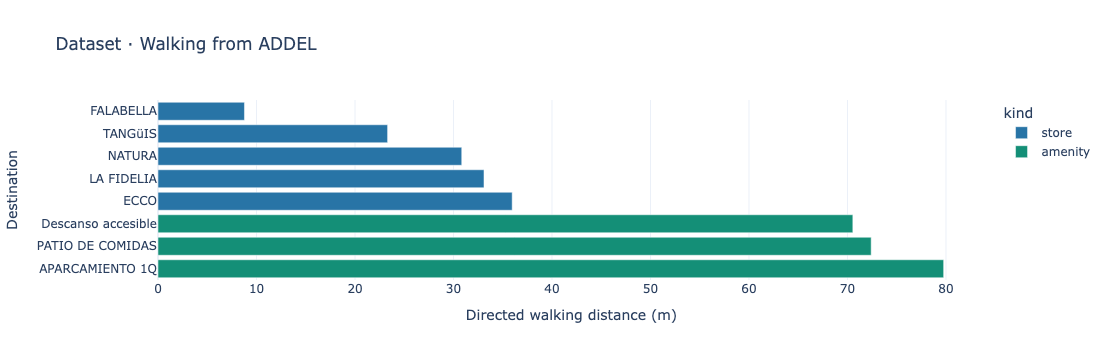

In [12]:
nearby_all = sql("""
SELECT r.origin_id, r.destination_id, c.label AS destination, c.kind, c.floors,
       c.categories, c.amenity_type, r.distance_m, r.floor_relationship
FROM location_routes r JOIN (SELECT * FROM destination_candidates UNION ALL SELECT * FROM amenity_candidates) c
ON c.entity_id=r.destination_id
WHERE r.origin_id=$origin AND r.status='reachable' AND ($max_m IS NULL OR r.distance_m <= $max_m)
ORDER BY r.distance_m, r.destination_id
""", {"origin": origin_id, "max_m": MAX_DISTANCE_M})
nearby_selected = pd.concat([
    nearby_all.loc[nearby_all.kind.eq("store")].head(K_STORES),
    nearby_all.loc[nearby_all.kind.eq("amenity")].head(K_AMENITIES),
]).sort_values(["distance_m", "destination_id"]).head(RESULT_LIMIT)
db.register("nearby_selected", nearby_selected)
nearby_paths = show_paths("walking", "SELECT * FROM nearby_selected ORDER BY distance_m, destination_id",
    ["origin_id", "destination_id"], [("walking_distance", False)], {}, walking=True)

distance_figure = px.bar(nearby_paths, x="distance_m", y="destination_id", color="kind", orientation="h",
    color_discrete_map=COLORS, hover_data=["destination", "floors", "categories", "amenity_type", "floor_relationship"],
    labels={"distance_m": "Directed walking distance (m)", "destination_id": "Destination"},
    title=f"Dataset · Walking from {labels[origin_id]}")
distance_figure.update_yaxes(tickmode="array", tickvals=nearby_paths.destination_id,
                            ticktext=nearby_paths.destination, autorange="reversed")
if nearby_paths.empty:
    distance_figure.add_annotation(text="No reachable destinations under these filters", showarrow=False)
distance_figure.update_layout(template="plotly_white")
display(distance_figure)

## 8 · How do walking distances compare across floors?

The table ranks reachable stores with disjoint floor memberships. The box plot
compares all qualifying reachable store destinations from the origin before the
display limit. Unknown memberships stay separate. Neither plot shows actual floor
transitions along the route. Unreachable and absent route rows are counted separately.

,origin_id,destination_id,destination,floors,categories,distance_m,origin
0,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-location:el_69c1a83d093c9b5967fcfb7e,DOLLAR CITY,Piso 3,Supermercados y Conveniencia | Tiendas por Dep...,65.19,ADDEL
1,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-location:el_69b0548a2c71c6f75252b8f8,TEN REN BUBBLE TEA,Piso 3,Gastronomía,71.88,ADDEL
2,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-location:el_69b0548a2c71c6f75252b9c8,CASA & IDEAS,Piso 3,Hogar y Decoración,72.95,ADDEL
3,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-location:el_69b0548a2c71c6f75252b9d9,UP BURGER,Piso 3,Gastronomía,79.47,ADDEL
4,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-location:el_6ab2d1af8c7bf2646835c091,PIA HOME,Piso 3,Hogar y Decoración,80.16,ADDEL
5,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-location:el_69b0548a2c71c6f75252b904,MC DONALDS,Piso 3,Gastronomía,81.76,ADDEL
6,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-location:el_69b0548a2c71c6f75252b9d6,ATARASHII,Piso 3,Servicios y Banca,82.30,ADDEL
7,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-location:el_69b0548a2c71c6f75252b9c9,IBERO LIBRERIAS,Piso 3,Entretenimiento y Cultura,85.10,ADDEL


,route_status,destinations
0,missing,12
1,reachable,333
2,unreachable,1


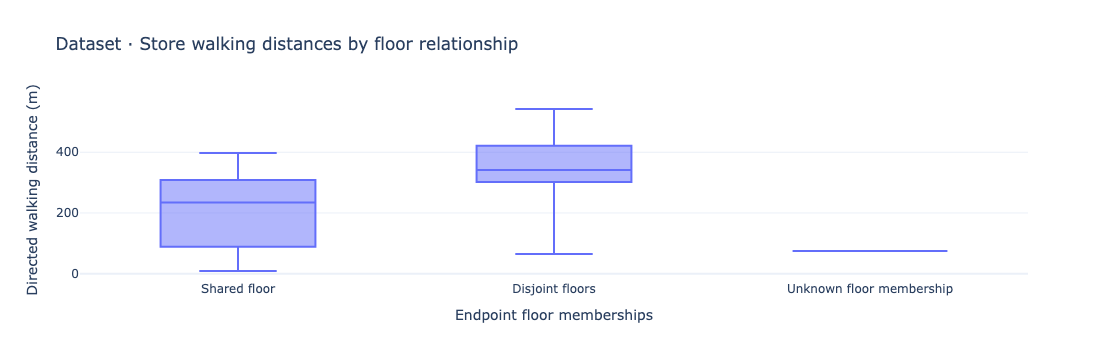

In [13]:
cross_floor_walking = show_paths("walking_across_floors", """
SELECT r.origin_id, r.destination_id, c.label AS destination, c.floors, c.categories, r.distance_m
FROM location_routes r JOIN destination_candidates c ON c.entity_id=r.destination_id
WHERE r.origin_id=$origin AND r.status='reachable' AND r.floor_relationship='Disjoint floors'
AND ($max_m IS NULL OR r.distance_m <= $max_m) ORDER BY r.distance_m, r.destination_id
""", ["origin_id", "destination_id"], [("walking_distance", False)], walking=True)
display(sql("""
SELECT coalesce(r.status, 'missing') AS route_status, count(*) AS destinations
FROM destination_candidates c LEFT JOIN location_routes r
ON r.destination_id=c.entity_id AND r.origin_id=$origin GROUP BY ALL ORDER BY route_status
""", {"origin": origin_id}))
floor_distance_figure = px.box(nearby_all.loc[nearby_all.kind.eq("store")],
    x="floor_relationship", y="distance_m", points=False,
    labels={"floor_relationship": "Endpoint floor memberships", "distance_m": "Directed walking distance (m)"},
    title="Dataset · Store walking distances by floor relationship")
if nearby_all.loc[nearby_all.kind.eq("store")].empty:
    floor_distance_figure.add_annotation(text="No reachable store destinations under these filters", showarrow=False)
floor_distance_figure.update_layout(template="plotly_white")
display(floor_distance_figure)

## 9 · Can I stop at an amenity between two stores?

`origin → amenity → destination`, using two reachable directed distance records.
Rank by the sum of both legs; an amenity is a chosen stop, not proof that the direct
route passes it. Additional metres compare that sum with the saved direct route
when reachable. Each leg uses SDK defaults; this is not an accessibility guarantee.

,origin_id,amenity_id,destination_id,amenity,amenity_type,amenity_floors,leg_1_m,leg_2_m,total_m,direct_status,direct_m,additional_m,origin,destination
0,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-location:el_69cc1d1049961600559200a9,enterprise-location:el_69c1a83d093c9b5967fcfb7e,APARCAMIENTO 1Q,Unspecified,Unknown,79.76,67.90,147.66,reachable,65.19,82.47,ADDEL,DOLLAR CITY
1,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-location:el_69cc1cb249961600559200a8,enterprise-location:el_69c1a83d093c9b5967fcfb7e,APARCAMIENTO 1P,Unspecified,Unknown,86.36,74.50,160.86,reachable,65.19,95.67,ADDEL,DOLLAR CITY
2,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-location:el_699850136461a334a10d3be2,enterprise-location:el_69c1a83d093c9b5967fcfb7e,Descanso accesible,accessible-washroom,Piso 1 | Piso 2 | Piso 3 | Piso 4 | Sotano 2 ...,70.54,103.54,174.09,reachable,65.19,108.90,ADDEL,DOLLAR CITY
3,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-location:el_69d744c6f6e39654df4be61c,enterprise-location:el_69c1a83d093c9b5967fcfb7e,PATIO DE COMIDAS,food-court,Unknown,72.40,106.22,178.62,reachable,65.19,113.43,ADDEL,DOLLAR CITY
4,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-location:el_69cd7185249c85a14b91bc0d,enterprise-location:el_69c1a83d093c9b5967fcfb7e,RIVA AGÜERO APARCAMIENTO,parking,Sotano 1,95.58,83.71,179.29,reachable,65.19,114.10,ADDEL,DOLLAR CITY
5,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-location:el_69cc1c8b49961600559200a7,enterprise-location:el_69c1a83d093c9b5967fcfb7e,APARCAMIENTO 1O,Unspecified,Unknown,109.68,97.80,207.47,reachable,65.19,142.29,ADDEL,DOLLAR CITY
6,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-location:el_69bc283d9f21369048a0d914,enterprise-location:el_69c1a83d093c9b5967fcfb7e,Directory - D3,interactive-display,Unknown,222.95,101.15,324.10,reachable,65.19,258.91,ADDEL,DOLLAR CITY
7,enterprise-location:el_69b0548a2c71c6f75252b9b8,enterprise-location:el_699c4338d7069214f2e40455,enterprise-location:el_69c1a83d093c9b5967fcfb7e,ATM MANTARO,atm,Piso 1,167.02,169.88,336.90,reachable,65.19,271.72,ADDEL,DOLLAR CITY


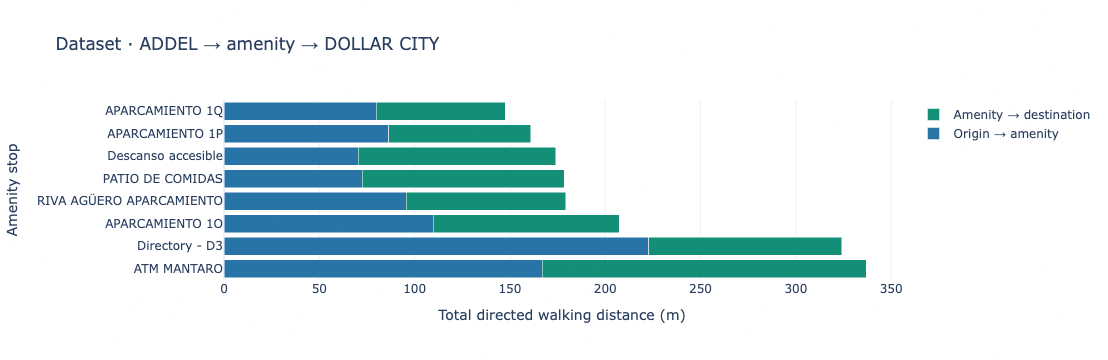

In [14]:
itinerary_paths = show_paths("amenity_itinerary", """
SELECT a.origin_id, a.destination_id AS amenity_id, b.destination_id,
       c.label AS amenity, c.amenity_type, c.floors AS amenity_floors,
       a.distance_m AS leg_1_m, b.distance_m AS leg_2_m,
       a.distance_m+b.distance_m AS total_m,
       coalesce(d.status, 'missing') AS direct_status,
       d.distance_m AS direct_m,
       CASE WHEN d.status='reachable' THEN a.distance_m+b.distance_m-d.distance_m END AS additional_m
FROM location_routes a JOIN amenity_candidates c ON c.entity_id=a.destination_id
JOIN location_routes b ON b.origin_id=a.destination_id AND b.destination_id=$destination
LEFT JOIN location_routes d ON d.origin_id=a.origin_id AND d.destination_id=b.destination_id
WHERE a.origin_id=$origin AND a.status='reachable' AND b.status='reachable'
AND ($max_m IS NULL OR a.distance_m+b.distance_m <= $max_m)
ORDER BY total_m, amenity_id
""", ["origin_id", "amenity_id", "destination_id"],
[("walking_distance", False), ("walking_distance", False)], walking=True)

itinerary_figure = go.Figure()
for column, title, color in [("leg_1_m", "Origin → amenity", "#2874a6"),
                              ("leg_2_m", "Amenity → destination", "#148f77")]:
    itinerary_figure.add_bar(x=itinerary_paths[column], y=itinerary_paths.amenity_id, name=title,
        orientation="h", marker_color=color,
        customdata=itinerary_paths[["amenity", "amenity_type", "total_m", "additional_m"]],
        hovertemplate="%{customdata[0]} · %{customdata[1]}<br>Leg: %{x:.2f} m"
                      "<br>Total: %{customdata[2]:.2f} m<br>Additional: %{customdata[3]:.2f} m<extra>%{fullData.name}</extra>")
itinerary_figure.update_yaxes(tickmode="array", tickvals=itinerary_paths.amenity_id,
                             ticktext=itinerary_paths.amenity, autorange="reversed", title="Amenity stop")
itinerary_figure.update_layout(barmode="stack", template="plotly_white", xaxis_title="Total directed walking distance (m)",
    title=f"Dataset · {labels[origin_id]} → amenity → {labels[destination_id] if destination_id else 'no destination selected'}")
if itinerary_paths.empty:
    itinerary_figure.add_annotation(text="No two-leg itinerary under these filters", showarrow=False)
display(itinerary_figure)

## Compare categories and floors

Counts are distinct stores per category and floor, using explicit memberships.
Multi-category and multi-floor stores contribute to each applicable cell, so cells
are not additive totals. This overview uses the complete snapshot, independent of controls.

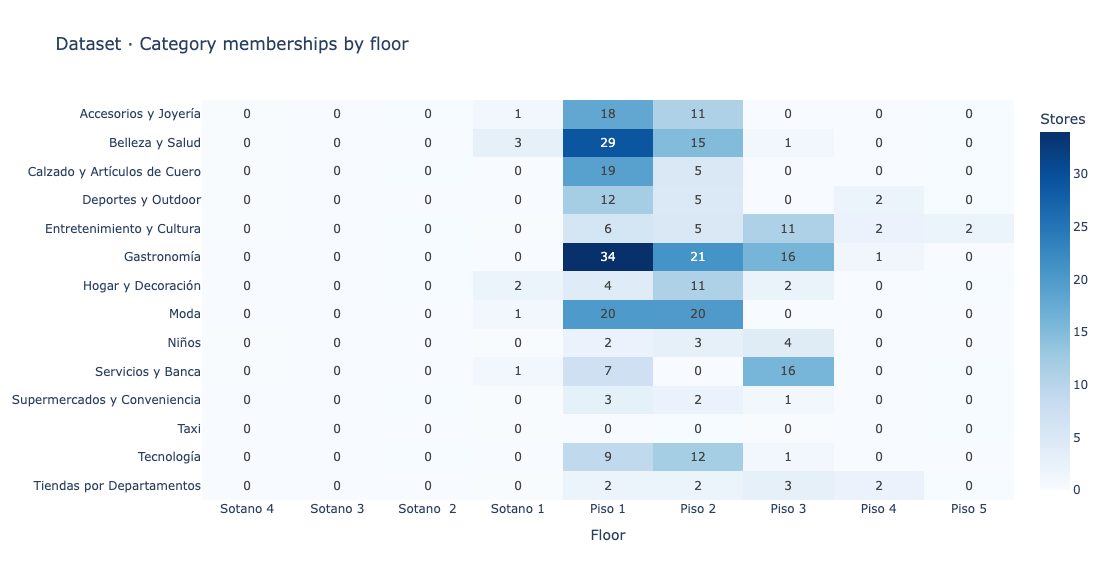

In [15]:
category_floor = sql("""
SELECT c.entity_id AS category_id, c.name AS category, f.entity_id AS floor_id,
       count(DISTINCT s.entity_id) AS stores
FROM stores s JOIN location_category_links lc ON lc.location_id=s.entity_id
JOIN categories c ON c.entity_id=lc.category_id
JOIN location_floors lf ON lf.location_id=s.entity_id JOIN floors f ON f.entity_id=lf.floor_entity_id
GROUP BY ALL
""")
floor_order = tables["floors"].sort_values(["elevation", "entity_id"])
category_order = tables["categories"].sort_values(["name", "entity_id"])
category_floor_matrix = category_floor.pivot(index="category_id", columns="floor_id", values="stores").reindex(
    index=category_order.entity_id, columns=floor_order.entity_id).fillna(0).astype(int)
heatmap_figure = go.Figure(go.Heatmap(z=category_floor_matrix.to_numpy(), x=floor_order.entity_id,
    y=category_order.entity_id, text=category_floor_matrix.to_numpy(), texttemplate="%{text}",
    customdata=[[[category, floor] for floor in floor_order.name] for category in category_order.name],
    hovertemplate="%{customdata[0]} · %{customdata[1]}<br>%{z} distinct stores<extra></extra>",
    colorscale="Blues", colorbar_title="Stores"))
heatmap_figure.update_xaxes(tickmode="array", tickvals=floor_order.entity_id, ticktext=floor_order.name, title="Floor")
heatmap_figure.update_yaxes(tickmode="array", tickvals=category_order.entity_id, ticktext=category_order.name, autorange="reversed")
heatmap_figure.update_layout(title="Dataset · Category memberships by floor", template="plotly_white", height=580)
display(heatmap_figure)

## Inspect a path family

Use the dropdown to switch examples. Each row is one displayed witness, with IDs
on hover. Repeated nodes in different rows preserve complete paths. Arrows show
**stored edge direction**, including reverse traversals; walking arrows show the
derived directed legs and measured metres. Positions are schematic, not map coordinates.

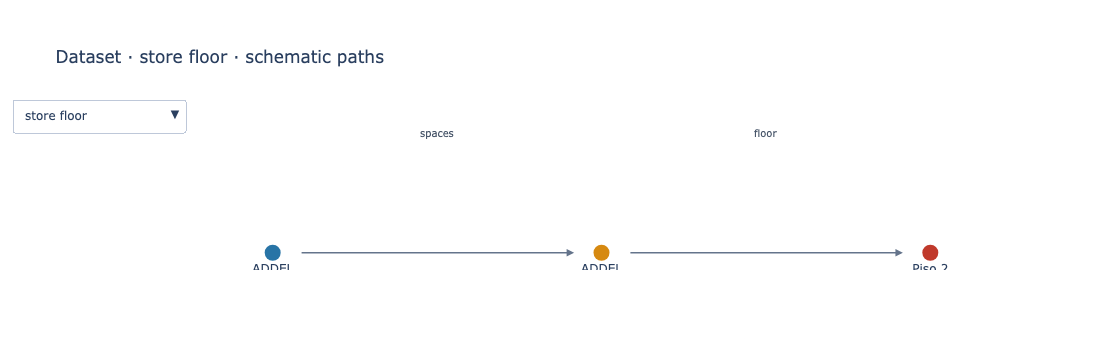

In [16]:
node_lookup = nodes.set_index("entity_id")
path_figure = go.Figure()
diagram_annotations = []
diagram_heights = []
for name, frame in witnesses.items():
    columns, edges, walking_path = path_specs[name]
    xs, ys, text, hover, colors = [], [], [], [], []
    annotations = []
    for row_number, row in enumerate(frame.to_dict("records")):
        for step, column in enumerate(columns):
            entity_id = row[column]
            node = node_lookup.loc[entity_id]
            xs.append(step * 3)
            ys.append(-row_number * 2)
            text.append(node.label if len(node.label) <= 25 else node.label[:22] + "…")
            hover.append(f"{node.label}<br>{node.kind}<br>{entity_id}")
            colors.append(COLORS.get(node.kind, "#777777"))
        for step, (relation, reverse) in enumerate(edges):
            left, right = step * 3 + 0.25, (step + 1) * 3 - 0.25
            if reverse:
                left, right = right, left
            edge_label = relation
            if walking_path:
                distance = row["distance_m" if len(edges) == 1 else f"leg_{step + 1}_m"]
                edge_label = f"{distance:.1f} m"
            annotations.extend([
                dict(x=right, y=-row_number * 2, ax=left, ay=-row_number * 2,
                     xref="x", yref="y", axref="x", ayref="y", text="", showarrow=True,
                     arrowhead=2, arrowwidth=1.5, arrowcolor="#64748b"),
                dict(x=step * 3 + 1.5, y=-row_number * 2 + 0.35, text=edge_label,
                     showarrow=False, font=dict(size=10, color="#475569")),
            ])
    if frame.empty:
        annotations.append(dict(x=0.5, y=0.5, xref="paper", yref="paper",
                                text="No matching paths under these filters", showarrow=False))
    path_figure.add_trace(go.Scatter(x=xs, y=ys, mode="markers+text", text=text,
        textposition="bottom center", hovertext=hover, hoverinfo="text", name=name,
        marker=dict(size=16, color=colors), visible=len(diagram_annotations) == 0))
    diagram_annotations.append(annotations)
    diagram_heights.append(max(340, len(frame) * 105 + 160))
buttons = []
for i, name in enumerate(witnesses):
    buttons.append(dict(label=name.replace("_", " "), method="update", args=[
        {"visible": [j == i for j in range(len(witnesses))]},
        {"annotations": diagram_annotations[i], "height": diagram_heights[i],
         "title": {"text": f"Dataset · {name.replace('_', ' ')} · schematic paths"},
         "xaxis.range": [-0.8, (len(path_specs[name][0]) - 1) * 3 + 0.8]},
    ]))
path_figure.update_layout(title="Dataset · store floor · schematic paths", template="plotly_white",
    annotations=diagram_annotations[0], height=diagram_heights[0], showlegend=False,
    updatemenus=[dict(buttons=buttons, direction="down", x=0, y=1.18)],
    margin=dict(l=80, r=90, t=125, b=70), xaxis=dict(visible=False, range=[-0.8, 6.8]),
    yaxis=dict(visible=False, autorange=True))
display(path_figure)

## Optional hosted Graphistry rendering

The local Plotly charts above are already available. `graphs` contains the full
source graph and one graph for each displayed path family. Source graphs retain
source edges; walking graphs contain only derived distance edges. GFQL unions
remain separately available in `gfql_results` for inspection.

To upload one selected graph, set `GRAPHISTRY_SERVER`, `GRAPHISTRY_PERSONAL_KEY_ID`,
and `GRAPHISTRY_PERSONAL_KEY_SECRET` in the kernel environment, choose `VIEW`, and
enable the switch. Raw metadata and geometry JSON are not included.

In [17]:
display(pd.DataFrame([{"graph": key, "nodes": len(g._nodes), "edges": len(g._edges)}
                      for key, g in graphs.items()]))

,graph,nodes,edges
0,full,3954,14047
1,store_floor,3,2
2,shared_space,1,0
3,shared_floor,19,18
4,shared_category,10,9
5,category_across_floors,10,9
6,floor_amenities,13,16
7,walking,9,8
8,walking_across_floors,9,8
9,amenity_itinerary,10,16


In [18]:
UPLOAD_TO_GRAPHISTRY = False
VIEW = "shared_floor"

if UPLOAD_TO_GRAPHISTRY:
    import os

    if VIEW not in graphs:
        raise ValueError(f"Choose VIEW from {list(graphs)}")
    required = ["GRAPHISTRY_SERVER","GRAPHISTRY_PERSONAL_KEY_ID","GRAPHISTRY_PERSONAL_KEY_SECRET"]
    if not all(os.environ.get(key) for key in required):
        raise ValueError("Set the Graphistry server and personal-key environment variables above.")
    selected_graph = graphs[VIEW]
    if selected_graph._nodes.empty:
        print("No selected nodes to render.")
    else:
        graphistry.register(api=3,protocol="https",server=os.environ["GRAPHISTRY_SERVER"],
                            personal_key_id=os.environ["GRAPHISTRY_PERSONAL_KEY_ID"],
                            personal_key_secret=os.environ["GRAPHISTRY_PERSONAL_KEY_SECRET"])
        display(selected_graph.plot(name=f"Dataset · {VIEW}",render="ipython"))
else:
    print("Graph prepared; hosted rendering disabled.")

Graph prepared; hosted rendering disabled.
